# EDA of titanic dataset with Python (Analysis)

## Titanic Survival: Exploratory Data Analysis and Prediction Model

This notebook explores the Titanic passenger dataset. It covers data loading, quality checks, cleaning, memory optimization, feature selection, outlier removal, feature engineering, survival analysis, and a Random Forest model that predicts survival.

#### 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif


## 2. Loading the Data

In [2]:
df = pd.read_csv('titanic.csv')
df.info()

original_memory_use = (df.memory_usage(deep= True).sum() / (1024 ** 2)).round(2)
print(f'\n\nMemory usage: \n{original_memory_use} MB\n\n')
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


Memory usage: 
0.12 MB




,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Preserving the Original Data

- Creates an independent copy of the DataFrame. All cleaning happens on `data`, so `df` stays unchanged for reference.


In [3]:
data = df.copy()

def data_quality(x):
    print('Checking Null values'.center(50,'='))
    null = x.isna().sum()
    print(null)
    print(f'Null pct: {(null/len(x)) * 100}')
    cols = x.columns.tolist()
    print('Unique Values'.center(50, '='))
    for i in cols:
        unique = x[i].nunique()
        print(f'{i} Columns have {unique} unique values')
        print("-" * 40)

data_quality(data)

===============Checking Null values===============
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Null pct: PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64
==================Unique Values===================
PassengerId Columns have 891 unique values
----------------------------------------
Survived Columns have 2 unique values
----------------------------------------
Pclass Columns have 3 unique values
----------------------------------------
Name Columns have 891 unique values
----------------------------------------
Sex Columns hav

## 4. Data Quality Check
- Dropping columns

| Column Name |Reason|
|----------|----------|
|Cabin|77% Missing Data|
|PassengerId|No Value  Adding|
|Name|No Value Adding|

- Filling Embarked columns with mode.
- Filling Age columns with median.


In [4]:
data = data.drop(columns= ['Cabin', 'Name', 'PassengerId'])
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data['Age'] = data['Age'].fillna(data['Age'].median())

data_quality(data)

===============Checking Null values===============
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Embarked    0
dtype: int64
Null pct: Survived    0.0
Pclass      0.0
Sex         0.0
Age         0.0
SibSp       0.0
Parch       0.0
Ticket      0.0
Fare        0.0
Embarked    0.0
dtype: float64
==================Unique Values===================
Survived Columns have 2 unique values
----------------------------------------
Pclass Columns have 3 unique values
----------------------------------------
Sex Columns have 2 unique values
----------------------------------------
Age Columns have 88 unique values
----------------------------------------
SibSp Columns have 7 unique values
----------------------------------------
Parch Columns have 7 unique values
----------------------------------------
Ticket Columns have 681 unique values
----------------------------------------
Fare Columns have 248 unique values
------------------

## 5. Dropping Columns and Filling Missing Values
- Handling Ticket Columns
- Now optimize the memory.
- converting `Sex`, `SibSp`, `Parch`, `Embarked` as Category columns.
- Int64 and Float64 into 32-bit types



In [5]:
data['Ticket_NUM'] = data['Ticket'].str.strip(",()[].\"'").str.split(" ").str[-1]
data['Ticket_CODE'] = data['Ticket'].str.strip(",()[].\"'").str.split(" ").str[0]
data = data.drop('Ticket',axis= 1)


## 6. Splitting the Ticket Column and Optimizing Memory

In [6]:
cat_cols = ['Sex','SibSp','Parch','Embarked','Ticket_CODE', 'Ticket_NUM']
int_col = data.select_dtypes('int').columns.tolist()
float_col = data.select_dtypes('float').columns.tolist()


for col in cat_cols:
    data[col] = data[col].astype('category')

for col in int_col:
    data[col] = data[col].astype('int32')

for col in float_col:
    data[col] = data[col].astype('float32')

optimized_memory_use = (data.memory_usage(deep= True).sum() / (1024 ** 2)).round(2)
print(f'\nMemory usage: \n{optimized_memory_use} MB\n')

reduced  = ((original_memory_use - optimized_memory_use)* 100/original_memory_use).round(2)
print(f'Memory Reduction:\n{reduced}%')

data.info()


Memory usage: 
0.04 MB

Memory Reduction:
66.67%
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Survived     891 non-null    int32   
 1   Pclass       891 non-null    int32   
 2   Sex          891 non-null    category
 3   Age          891 non-null    float32 
 4   SibSp        891 non-null    int32   
 5   Parch        891 non-null    int32   
 6   Fare         891 non-null    float32 
 7   Embarked     891 non-null    category
 8   Ticket_NUM   891 non-null    category
 9   Ticket_CODE  891 non-null    category
dtypes: category(4), float32(2), int32(4)
memory usage: 42.7 KB


## 7. Encoding and Feature Selection
- Scores each feature against the target and returns the selected columns.
- The returned values are not used here, because the script only needs the scores and the selected names.

In [7]:
data['Sex_Encoded'] = data['Sex'].cat.codes.astype('int8')
data['Embarked_encoded'] = data['Embarked'].cat.codes.astype('int8')



X = data.select_dtypes(['number']).drop('Survived', axis= 1)
y = data['Survived']

selector = SelectKBest(score_func= f_classif, k= 4)
selector.fit_transform(X, y)

print("Feature scores:")
for feature, score in zip(X.columns, selector.scores_):
    print(f"{feature}: {score:.3f}")


selected_features = X.columns[selector.get_support()].tolist()
print("\nSelected top 4 features:", selected_features)

Feature scores:
Pclass: 115.031
Age: 3.762
SibSp: 1.111
Parch: 5.963
Fare: 63.031
Sex_Encoded: 372.406
Embarked_encoded: 25.717

Selected top 4 features: ['Pclass', 'Fare', 'Sex_Encoded', 'Embarked_encoded']


## 8. Correlation Matrix

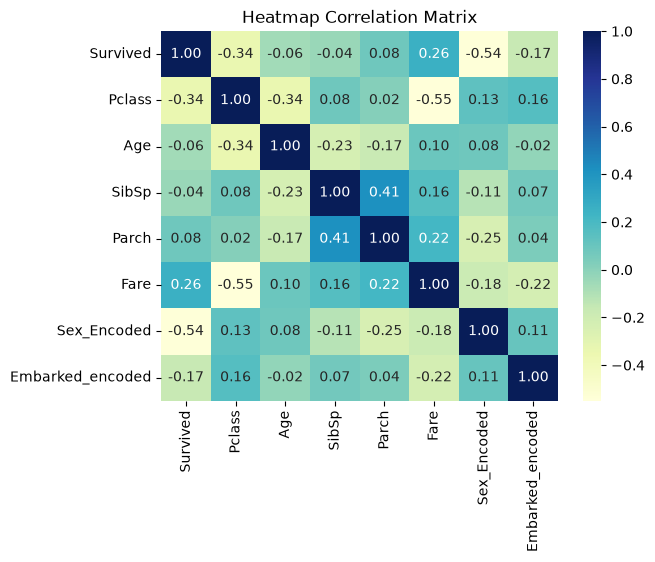

In [8]:
corr_matrix = data.select_dtypes(include=['number']).corr()

ax = sns.heatmap(data= corr_matrix, annot= True, fmt= '.2f', cmap= 'YlGnBu')
ax.set_title('Heatmap Correlation Matrix');

## 9. Summary Statistics

In [9]:
data.describe(include= 'all')

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Ticket_NUM,Ticket_CODE,Sex_Encoded,Embarked_encoded
count,891.000000,891.000000,891,891.000000,891.000000,891.000000,891.000000,891,891,891,891.000000,891.000000
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,679,557,NaN,NaN
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,1601,PC,NaN,NaN
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,646,7,60,NaN,NaN
mean,0.383838,2.308642,NaN,29.361582,0.523008,0.381594,32.204208,NaN,NaN,NaN,0.647587,1.536476
std,0.486592,0.836071,NaN,13.019696,1.102743,0.806057,49.693432,NaN,NaN,NaN,0.477990,0.791503
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000
25%,0.000000,2.000000,NaN,22.000000,0.000000,0.000000,7.910400,NaN,NaN,NaN,0.000000,1.000000
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,1.000000,2.000000
75%,1.000000,3.000000,NaN,35.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,1.000000,2.000000


## 10. Outlier Detection

- Only Fare and Age have variability

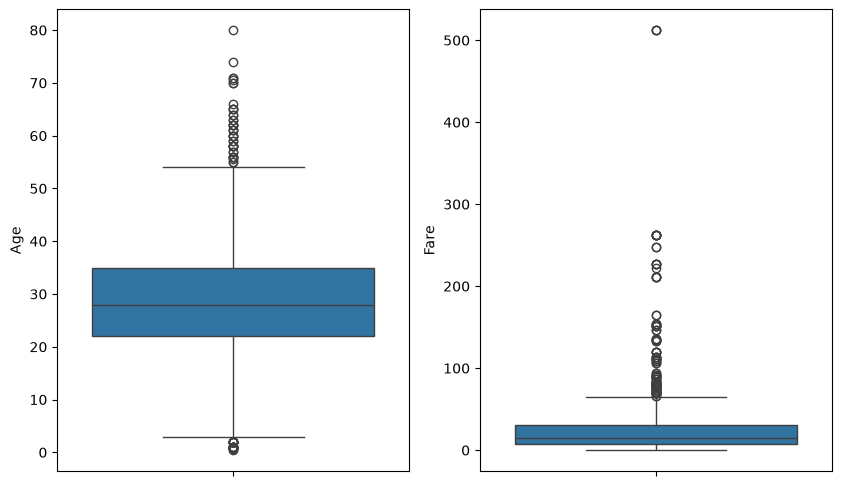

In [10]:
col = ['Age','Fare']

fig, ax = plt.subplots(1, 2, figsize= (10,6))
ax = ax.flatten()
for i, col_name in enumerate(col):
    sns.boxplot(data= data[col_name], ax= ax[i])

## 11. Removing Outliers

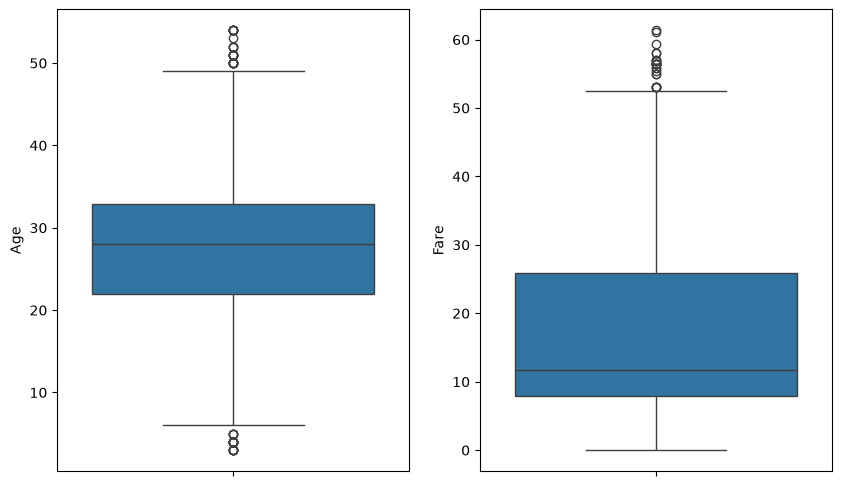

In [11]:
def removing_outliers(df, x):
    q1 = df[x].quantile(0.25)
    q3 = df[x].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + iqr * 1.5
    lower_bound = q1 - iqr * 1.5
    df = df[(df[x] <= upper_bound) & (df[x] >= lower_bound)]
    return df

for i in col:
    data = removing_outliers(df= data, x= i)

fig, ax = plt.subplots(1, 2, figsize= (10,6))
ax = ax.flatten()
for i, col_name in enumerate(col):
    sns.boxplot(data= data[col_name], ax= ax[i])

In [12]:
data.describe(include='all')

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Ticket_NUM,Ticket_CODE,Sex_Encoded,Embarked_encoded
count,718.000000,718.000000,718,718.000000,718.000000,718.000000,718.000000,718,718,718,718.000000,718.000000
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,596,499,NaN,NaN
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,1601,C.A.,NaN,NaN
freq,NaN,NaN,489,NaN,NaN,NaN,NaN,543,7,24,NaN,NaN
mean,0.334262,2.512535,NaN,28.079388,0.413649,0.317549,17.193205,NaN,NaN,NaN,0.681058,1.611421
std,0.472061,0.715818,NaN,10.012369,0.855001,0.784792,13.244508,NaN,NaN,NaN,0.466391,0.726646
min,0.000000,1.000000,NaN,3.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000
25%,0.000000,2.000000,NaN,22.000000,0.000000,0.000000,7.889575,NaN,NaN,NaN,0.000000,2.000000
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,11.750000,NaN,NaN,NaN,1.000000,2.000000
75%,1.000000,3.000000,NaN,32.875000,1.000000,0.000000,25.928149,NaN,NaN,NaN,1.000000,2.000000


## 12. Feature Engineering

In [13]:
age_bins = [0, 12, 19, 59, np.inf]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']
data['Age_group'] = pd.cut(data['Age'], bins=age_bins, labels=age_labels, right=True)

data['Fare_group'] = pd.qcut(data['Fare'], q=4, labels=['Low', 'Medium', 'High', 'Very High'])

data['Family_Size'] = data['SibSp'] + data['Parch'] + 1
data['IsAlone'] = (data['Family_Size'] == 1).astype(int)

data = data.drop(['SibSp','Parch'], axis= 1)

data.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,Ticket_NUM,Ticket_CODE,Sex_Encoded,Embarked_encoded,Age_group,Fare_group,Family_Size,IsAlone
0,0,3,male,22.0,7.250000,S,21171,A/5,1,2,Adult,Low,2,0
2,1,3,female,26.0,7.925000,S,3101282,STON/O2.,0,2,Adult,Medium,1,1
3,1,1,female,35.0,53.099998,S,113803,113803,0,2,Adult,Very High,2,0
4,0,3,male,35.0,8.050000,S,373450,373450,1,2,Adult,Medium,1,1
5,0,3,male,28.0,8.458300,Q,330877,330877,1,1,Adult,Medium,1,1


## 13. Survival Rate Chart Function

#### cross_tab_chart(df, x)
- Plots the survival rate (as a percentage) for each category of column `x`, split by `Sex`, as a grouped bar chart. It also returns the underlying table.

#### Retrun
- A table with one row per category of `x` and one column per sex (`female`, `male`). Each value is the survival rate in percent.
- `pd.crosstab(df[x], df['Sex'], values=df['Survived'], aggfunc='mean')` groups the rows by `x` and `Sex`, then takes the mean of `Survived` in each group. Because `Survived` is coded 0 or 1, the mean is the survival rate.
- `.round(2) * 100` rounds each rate to two decimals, then multiplies by 100. For example, `0.9615` becomes `0.96` and then `96.0`.
- Creates grouped bars, with one group per category of `x` and one bar per sex. The horizontal grid lines are drawn at 30% opacity.


In [14]:
def cross_tab_chart(df, x):
    ct = pd.crosstab(df[x], df['Sex'], values=df['Survived'], aggfunc='mean').round(2) * 100
    title = f'Survival Rate (%) by {x} and Sex'
    ylabel = 'Survival rate'
    fmt = '%.2f'
    
    ax = ct.plot(kind='bar', figsize=(10, 5), width=0.8, rot=0)

    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=2, fontsize=8)

    ax.set_title(title)
    ax.set_xlabel(x)
    ax.set_ylabel(ylabel)
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    return ct


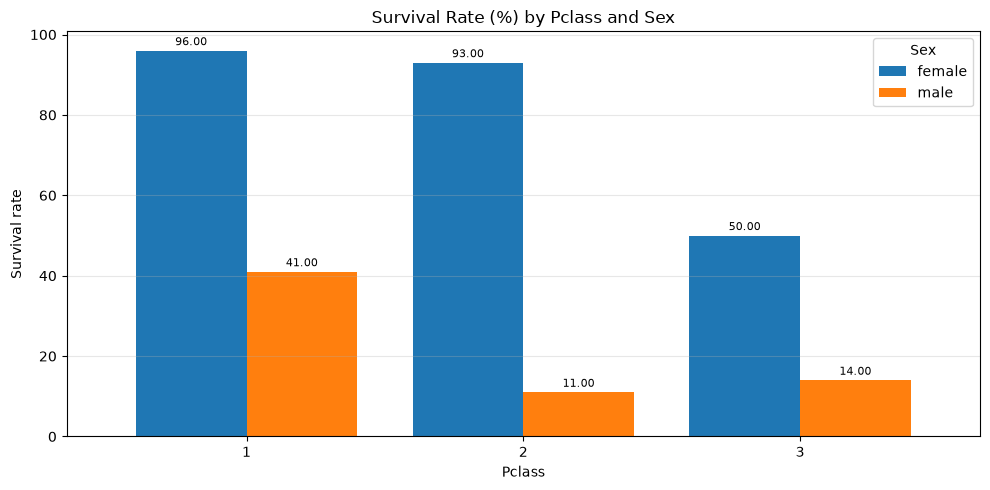

Sex,female,male
Pclass,,
1,96.0,41.0
2,93.0,11.0
3,50.0,14.0


In [15]:
cross_tab_chart(df= data, x= 'Pclass')

1. Survival Rate by Pclass and Sex
    - Female passengers had significantly higher survival rates than males across all passenger classes, with the highest female survival rate in 1st class (96.15%).
    - Male survival rates were considerably lower, with the lowest rate in 2nd class (10.99%).

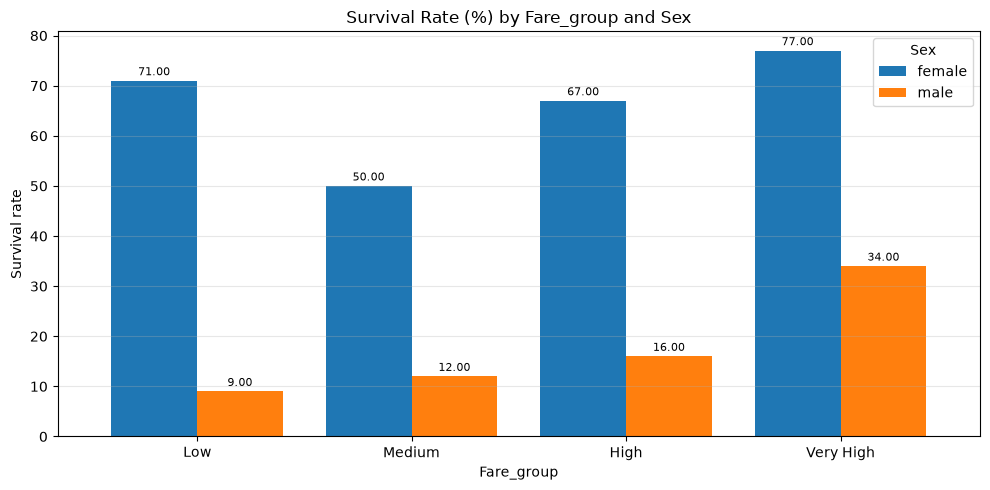

Sex,female,male
Fare_group,,
Low,71.0,9.0
Medium,50.0,12.0
High,67.0,16.0
Very High,77.0,34.0


In [16]:
cross_tab_chart(df= data, x= 'Fare_group')

2. Survival Rate by Fare Group and Sex
    - Female passengers had higher survival rates than males across all fare groups, with the highest female survival rate in the Very High fare group (77.46%).
    - Male passengers in the Very High fare group had the highest male survival rate (33.94%), while the Low fare group had the lowest (9.42%).

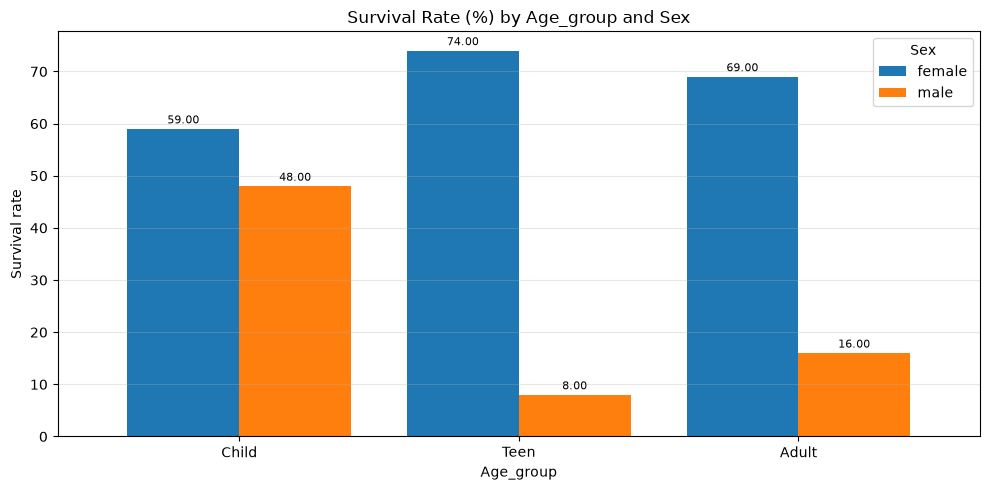

Sex,female,male
Age_group,,
Child,59.0,48.0
Teen,74.0,8.0
Adult,69.0,16.0


In [17]:
cross_tab_chart(df= data, x= 'Age_group')

3. Survival Rate by Age Group and Sex
    - Female passengers had higher survival rates than males in every age group, with Teen females having the highest survival rate (74.29%).
    - Among males, Children had the highest survival rate (47.62%), while Teen males had the lowest (8.33%)

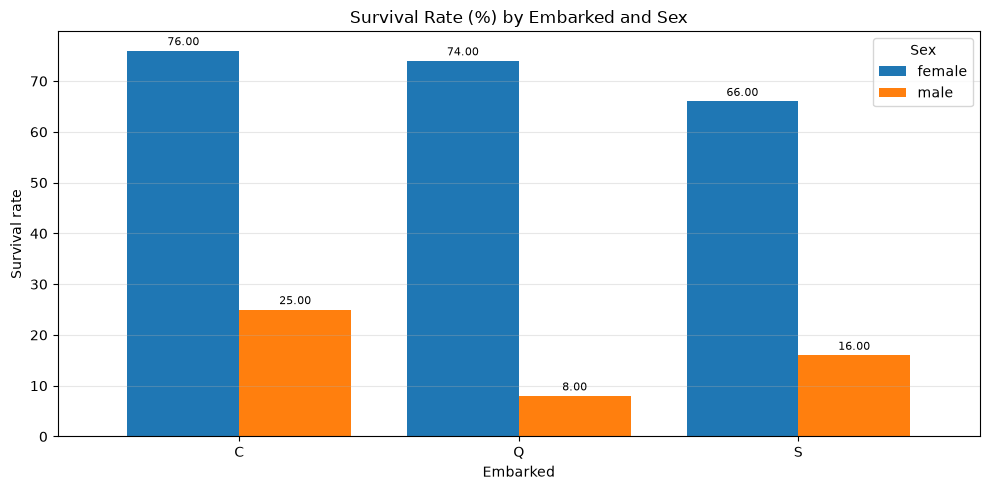

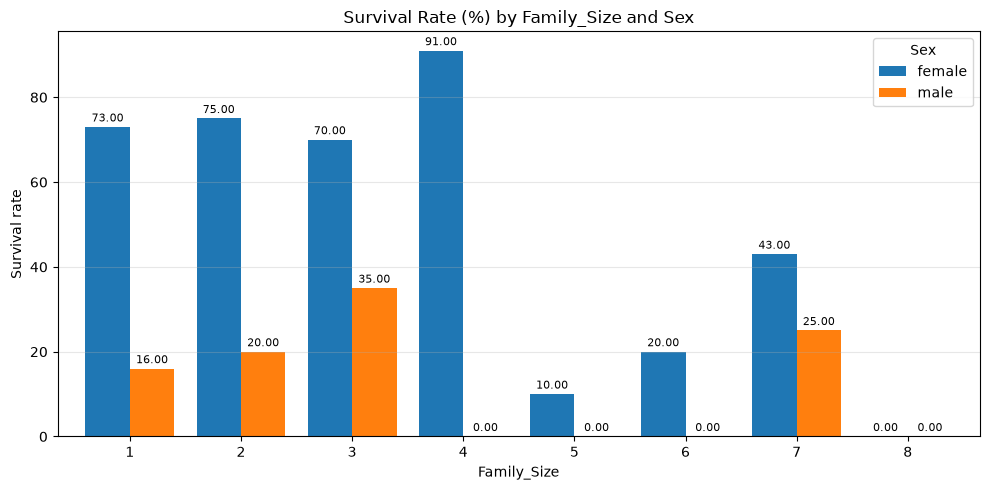

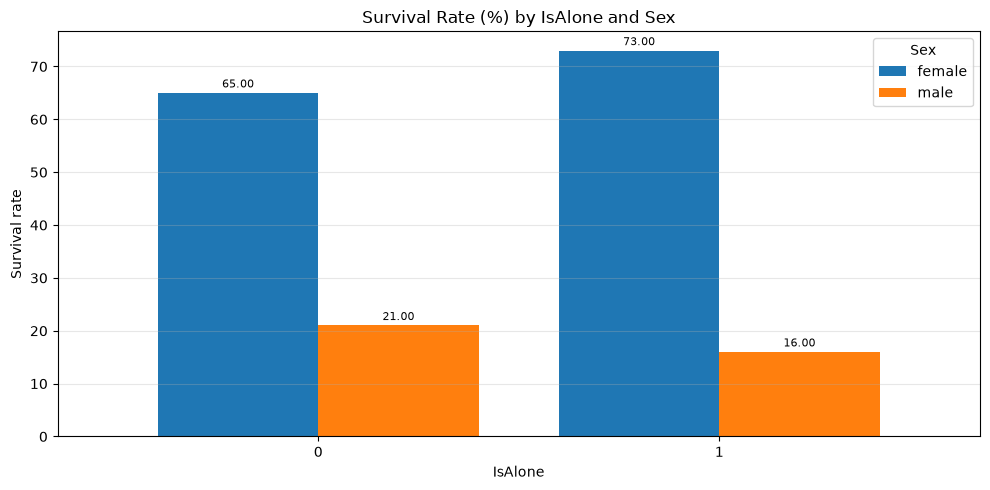

In [18]:
columns = ['Embarked', 'Family_Size', 'IsAlone']

for col in columns:
    cross_tab_chart(df= data, x= col)

- Embarked: `C` had the highest survival for both sexes, while `Q` men had the lowest at 8%, so port matters less than sex and probably reflects class differences.

- Family size: Small families of 2 to 4 survived best, while lone travellers and large families (5 or more) did worse.

- IsAlone: Men with family survived more often (21%) than men alone (16%), while women alone did slightly better (73%) than women with family (65%).

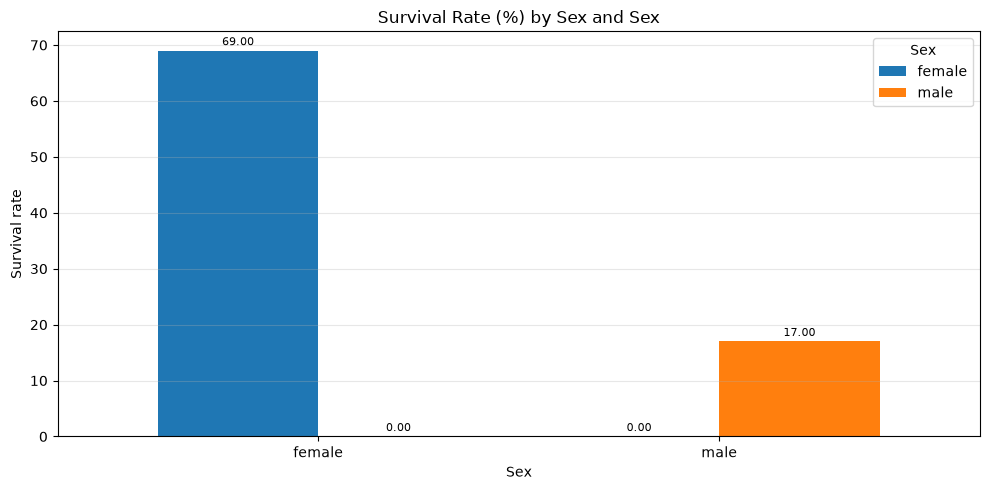

Sex,female,male
Sex,,
female,69.0,NaN
male,NaN,17.0


In [19]:
cross_tab_chart(df=data, x= 'Sex')

### Combined Insight

- Gender was a major factor associated with survival, as female passengers consistently had higher survival rates than male passengers across all categories.
- Passenger class and fare group were important factors, with 1st-class passengers and those paying very high fares generally experiencing better survival outcomes.
- Age also influenced survival, as children had the highest male survival rate, while teen males had the lowest.
- Embarkation location showed some variation in survival rates, with passengers embarking from `C` generally showing better survival outcomes.
- Family size: Small families of 2 to 4 survived best, while lone travelers  and large families (5 or more) did worse.
- IsAlone: Men with family survived more often (21%) than men alone (16%), while women alone did slightly better (73%) than women with family (65%).

Overall, female gender, higher passenger class, higher fare, and younger age (particularly childhood) were associated with better survival rates in the displayed data.

## 16. Prediction Model

### 16.1 Imports

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             RocCurveDisplay, accuracy_score)
from sklearn.model_selection import cross_val_score


### 16.2 Preparing the Features

In [21]:
model_data = data.drop(['Ticket_CODE','Ticket_NUM','Family_Size', 'IsAlone', 'Sex_Encoded','Embarked_encoded'], axis= 1).copy()

# data.head()
model_data = pd.get_dummies(model_data)
model_data.head()

,Survived,Pclass,Age,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Age_group_Child,Age_group_Teen,Age_group_Adult,Age_group_Senior,Fare_group_Low,Fare_group_Medium,Fare_group_High,Fare_group_Very High
0,0,3,22.0,7.250000,False,True,False,False,True,False,False,True,False,True,False,False,False
2,1,3,26.0,7.925000,True,False,False,False,True,False,False,True,False,False,True,False,False
3,1,1,35.0,53.099998,True,False,False,False,True,False,False,True,False,False,False,False,True
4,0,3,35.0,8.050000,False,True,False,False,True,False,False,True,False,False,True,False,False
5,0,3,28.0,8.458300,False,True,False,True,False,False,False,True,False,False,True,False,False


### 16.3 Splitting the Data

In [30]:
X= model_data.drop('Survived', axis= 1)
y= model_data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.25, random_state= 55)


### 16.4 Training the Model

In [31]:
rf_model = RandomForestClassifier(n_estimators= 150, random_state= 75)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",75
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

### 16.5 Making Predictions

In [32]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

### 16.6 Evaluating the Model

Accuracy: 0.833
ROC-AUC:  0.894
                 precision    recall  f1-score   support

Did not survive       0.91      0.85      0.88       126
       Survived       0.69      0.80      0.74        54

       accuracy                           0.83       180
      macro avg       0.80      0.82      0.81       180
   weighted avg       0.84      0.83      0.84       180



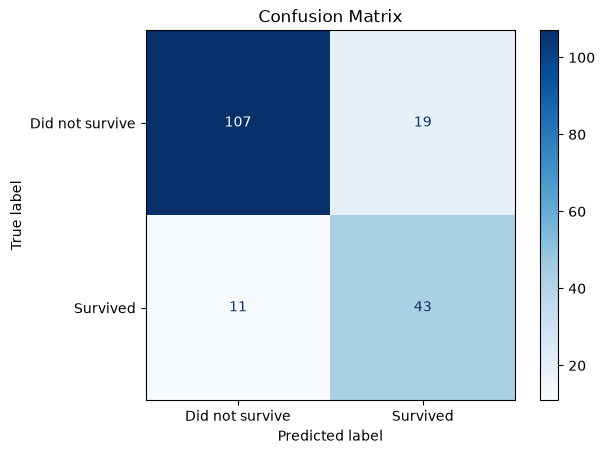

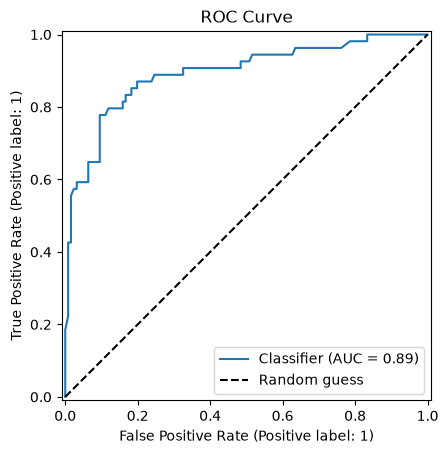

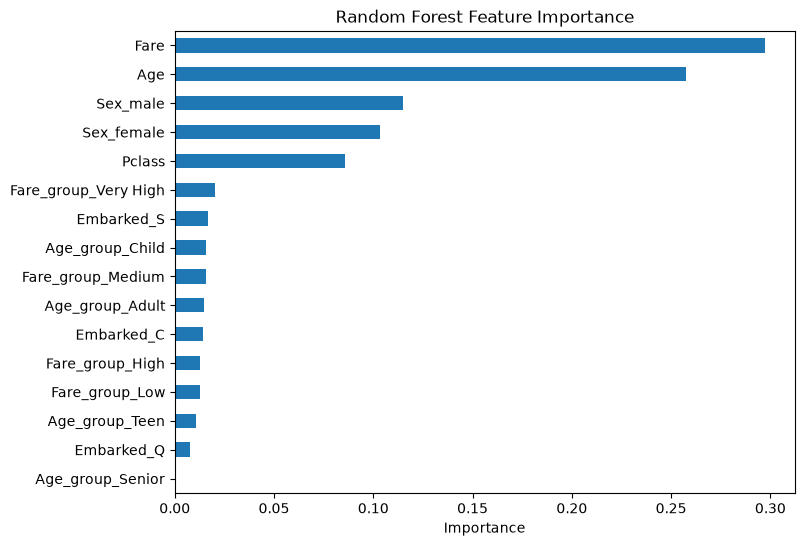

In [33]:
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'ROC-AUC:  {roc_auc_score(y_test, y_prob):.3f}')
print(classification_report(y_test, y_pred, target_names=['Did not survive', 'Survived']))


ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
    display_labels=['Did not survive', 'Survived'], cmap='Blues')
plt.title('Confusion Matrix')
plt.show()


RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.title('ROC Curve')
plt.legend()
plt.show()


importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 6))
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.show()

## 17. Notes

- Outliers were removed before the train/test split. For a stricter evaluation, apply the outlier filter only to the training set.
- Cross-validation is a useful next step to confirm the test results are stable across different splits.